<a href="https://colab.research.google.com/github/aditiprasannna/DLG-lab/blob/main/lab5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras import models, layers

(x_train, y_train), (x_test, y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
PIXEL_MAX = 255.0

x_train = x_train.astype('float32') / PIXEL_MAX
x_test = x_test.astype('float32') / PIXEL_MAX

In [ ]:
TIME_STEPS = 28
FEATURES = 28

x_train = x_train.reshape(-1, TIME_STEPS, FEATURES)
x_test = x_test.reshape(-1, TIME_STEPS, FEATURES)

In [ ]:
NUM_CLASSES = 10

y_train = tf.keras.utils.to_categorical(y_train, NUM_CLASSES)
y_test = tf.keras.utils.to_categorical(y_test, NUM_CLASSES)

In [ ]:
RNN_UNITS = 128

model = models.Sequential()

model.add(layers.SimpleRNN(
    RNN_UNITS,
    activation='relu',
    input_shape=(TIME_STEPS, FEATURES)
))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
OUT_UNITS = 10

model.add(layers.Dense(
    OUT_UNITS,
    activation=None
))

In [ ]:
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.CategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)


In [ ]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_data=(x_test, y_test)
)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 13s 23ms/step - accuracy: 0.8155 - loss: 0.5565 - val_accuracy: 0.9353 - val_loss: 0.2175
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - accuracy: 0.9430 - loss: 0.1906 - val_accuracy: 0.9514 - val_loss: 0.1704
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 21s 24ms/step - accuracy: 0.9578 - loss: 0.1452 - val_accuracy: 0.9633 - val_loss: 0.1294
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - accuracy: 0.9615 - loss: 0.1310 - val_accuracy: 0.9575 - val_loss: 0.1468
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 23ms/step - accuracy: 0.9674 - loss: 0.1120 - val_accuracy: 0.9724 - val_loss: 0.0907
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 23ms/step - accuracy: 0.9706 - loss: 0.0997 - val_accuracy: 0.9726 - val_loss: 0.0914
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - accuracy: 0.9734 - loss: 0.0903 - val_accuracy: 0.9736 - val_loss: 0.0926
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - accuracy: 0.9750 - loss: 0.0856 - 

In [ ]:

import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras import models, layers

# Load dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Q1a: Normalize pixels
PIXEL_MAX = 255.0
x_train = x_train.astype('float32') / PIXEL_MAX
x_test = x_test.astype('float32') / PIXEL_MAX

# Q1b: Reshape data
TIME_STEPS = 28
FEATURES = 28

x_train = x_train.reshape(-1, TIME_STEPS, FEATURES)
x_test = x_test.reshape(-1, TIME_STEPS, FEATURES)

# Q1c: One-hot encoding
NUM_CLASSES = 10

y_train = tf.keras.utils.to_categorical(y_train, NUM_CLASSES)
y_test = tf.keras.utils.to_categorical(y_test, NUM_CLASSES)

# Q2a: Build RNN model
RNN_UNITS = 128
OUT_UNITS = 10

model = models.Sequential()

model.add(layers.SimpleRNN(
    RNN_UNITS,
    activation='relu',
    input_shape=(TIME_STEPS, FEATURES)
))

# Q2b: Dense layer
model.add(layers.Dense(OUT_UNITS, activation=None))

# Q3a: Compile model
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.CategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

# Q3b: Train model
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_data=(x_test, y_test)
)

# Evaluate model
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", test_accuracy)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.8162 - loss: 0.5642 - val_accuracy: 0.9283 - val_loss: 0.2422
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9417 - loss: 0.1917 - val_accuracy: 0.9575 - val_loss: 0.1370
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9553 - loss: 0.1446 - val_accuracy: 0.9577 - val_loss: 0.1430
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9636 - loss: 0.1238 - val_accuracy: 0.9656 - val_loss: 0.1166
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9669 - loss: 0.1095 - val_accuracy: 0.9652 - val_loss: 0.1095
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9701 - loss: 0.1019 - val_accuracy: 0.9687 - val_loss: 0.0997
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9728 - loss: 0.0919 - val_accuracy: 0.9744 - val_loss: 0.0928
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9738 - loss: 0.0903 - val_accuracy: 

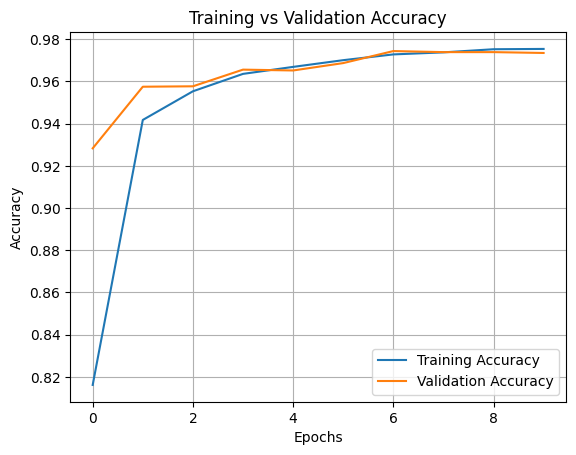

In [2]:

import matplotlib.pyplot as plt

# Plot training and validation accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

